# StreamFlix Content Analytics

## Phase 2 — Exploratory Data Analysis (EDA)

This phase analyzes viewing patterns, content performance, subscriber behavior, device usage, completion rates, and review sentiment using the StreamFlix datasets.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving watch_history.csv to watch_history.csv
Saving watchlist.csv to watchlist.csv
Saving subscribers.csv to subscribers.csv
Saving titles.csv to titles.csv
Saving ratings.csv to ratings.csv
Saving reviews.csv to reviews.csv


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

subscribers = pd.read_csv("/content/subscribers.csv")
titles = pd.read_csv("/content/titles.csv")
watch_history = pd.read_csv("/content/watch_history.csv")
ratings = pd.read_csv("/content/ratings.csv")
reviews = pd.read_csv("/content/reviews.csv")
watchlist = pd.read_csv("/content/watchlist.csv")

In [ ]:
watch_history["watch_date"] = pd.to_datetime(watch_history["watch_date"])
subscribers["signup_date"] = pd.to_datetime(subscribers["signup_date"])
reviews["review_date"] = pd.to_datetime(reviews["review_date"])

In [ ]:
monthly_sessions = (
    watch_history
    .groupby(watch_history["watch_date"].dt.to_period("M"))
    .size()
    .reset_index(name="sessions")
)

monthly_sessions["month"] = monthly_sessions["watch_date"].astype(str)

monthly_sessions.head()

,watch_date,sessions,month
0,2017-03,1,2017-03
1,2017-04,1,2017-04
2,2017-05,1,2017-05
3,2017-07,1,2017-07
4,2017-09,2,2017-09


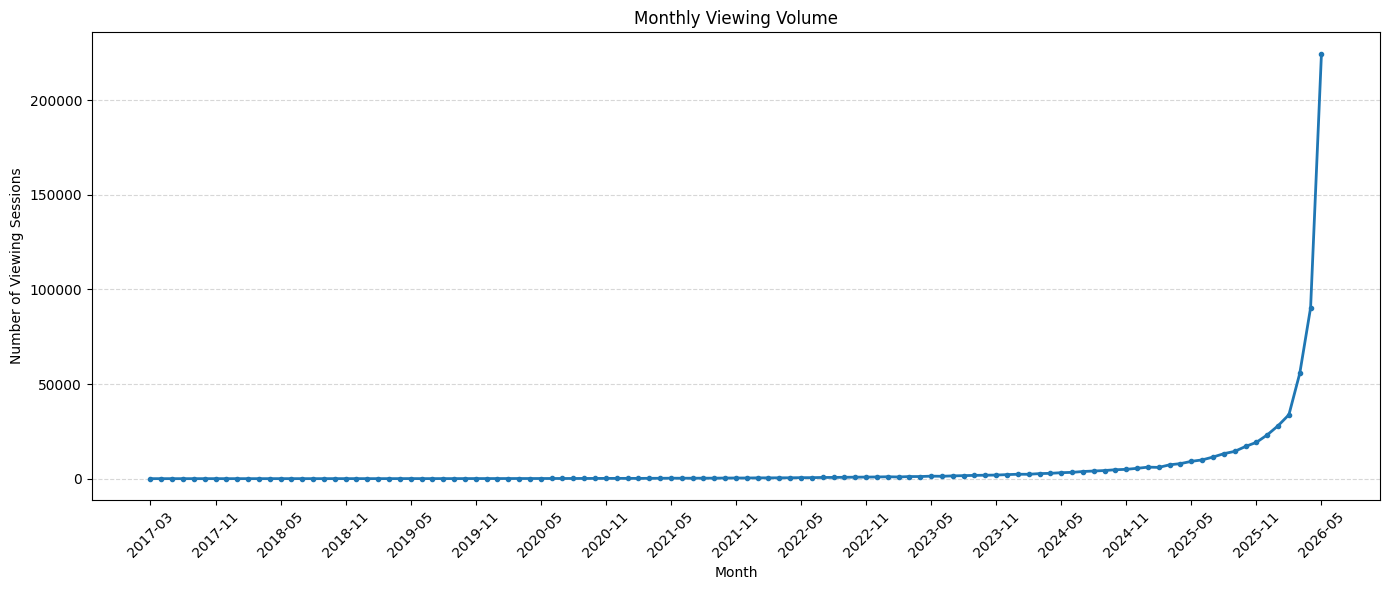

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sessions["month"],
    monthly_sessions["sessions"],
    marker="o",
    linewidth=2,
    markersize=3
)

plt.title("Monthly Viewing Volume")
plt.xlabel("Month")
plt.ylabel("Number of Viewing Sessions")

# Show every 6th month label
plt.xticks(
    range(0, len(monthly_sessions), 6),
    monthly_sessions["month"].iloc[::6],
    rotation=45
)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "/content/01_monthly_viewing_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Viewing activity shows a strong upward trend over time, with the highest number of viewing sessions recorded in May 2026 (224,696 sessions). April 2026 was the second-busiest month with 90,383 sessions, followed by March 2026 with 55,665 sessions. Overall, viewing volume increased substantially during the later months of the dataset.

In [ ]:
monthly_sessions.sort_values(
    "sessions",
    ascending=False
).head(5)

,watch_date,sessions,month
108,2026-05,224696,2026-05
107,2026-04,90383,2026-04
106,2026-03,55665,2026-03
105,2026-02,33795,2026-02
104,2026-01,27970,2026-01


In [ ]:
monthly_watch_hours = (
    watch_history
    .groupby(watch_history["watch_date"].dt.to_period("M"))["watch_duration_min"]
    .sum()
    .reset_index()
)

monthly_watch_hours["watch_hours"] = (
    monthly_watch_hours["watch_duration_min"] / 60
)

monthly_watch_hours["month"] = (
    monthly_watch_hours["watch_date"].astype(str)
)

monthly_watch_hours.head()

,watch_date,watch_duration_min,watch_hours,month
0,2017-03,286.4,4.773333,2017-03
1,2017-04,264.0,4.400000,2017-04
2,2017-05,865.0,14.416667,2017-05
3,2017-07,84.8,1.413333,2017-07
4,2017-09,156.6,2.610000,2017-09


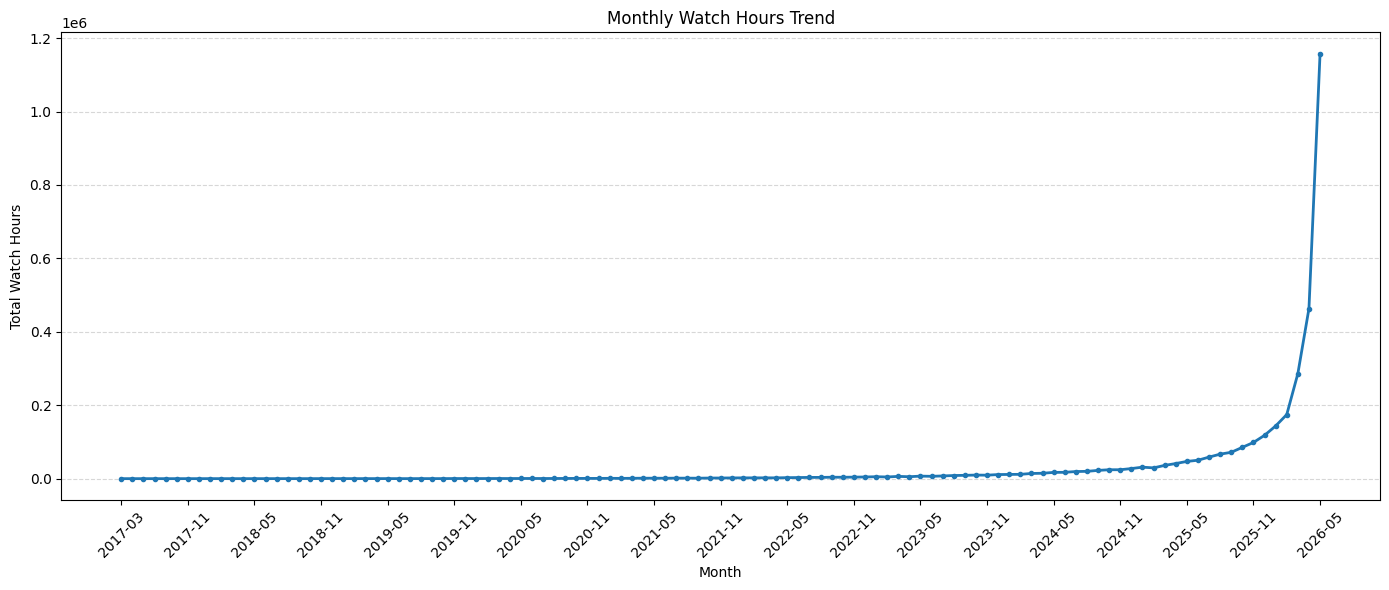

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_watch_hours["month"],
    monthly_watch_hours["watch_hours"],
    marker="o",
    linewidth=2,
    markersize=3
)

plt.title("Monthly Watch Hours Trend")
plt.xlabel("Month")
plt.ylabel("Total Watch Hours")

# Show every 6th month label
plt.xticks(
    range(0, len(monthly_watch_hours), 6),
    monthly_watch_hours["month"].iloc[::6],
    rotation=45
)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.savefig(
    "/content/02_monthly_watch_hours_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
yearly_watch_hours = (
    watch_history
    .groupby(watch_history["watch_date"].dt.year)["watch_duration_min"]
    .sum()
    / 60
)

yearly_watch_hours

,watch_duration_min
watch_date,
2017,4.575667e+01
2018,5.835400e+02
2019,1.679413e+03
2020,5.471778e+03
2021,1.543533e+04
2022,3.735396e+04
2023,8.966582e+04
2024,2.239940e+05
2025,7.339391e+05


### Observation

Total watch hours increased consistently year over year, rising from approximately 45.8 hours in 2017 to over 2.22 million hours in 2026. The growth became particularly strong from 2023 onward, with 2026 recording the highest total watch time. This indicates a substantial increase in overall platform viewing activity over the period.

In [ ]:
monthly_watch_hours.sort_values(
    "watch_hours",
    ascending=False
).head(5)

,watch_date,watch_duration_min,watch_hours,month
108,2026-05,69467154.0,1.157786e+06,2026-05
107,2026-04,27800237.5,4.633373e+05,2026-04
106,2026-03,17165302.7,2.860884e+05,2026-03
105,2026-02,10473927.2,1.745655e+05,2026-02
104,2026-01,8611319.7,1.435220e+05,2026-01


### Observation

Monthly watch hours show a strong upward trend, with the highest watch time recorded in May 2026 at approximately 1.16 million hours. April 2026 followed with approximately 463,337 hours, while March 2026 recorded approximately 286,088 hours. Overall, the later months show substantially higher viewing activity than the earlier period.

In [ ]:
print(titles[["title_id", "primary_genre"]].head())
print(watch_history[["title_id", "watch_duration_min"]].head())

    title_id primary_genre
0  TTL200000        Comedy
1  TTL200001       Fantasy
2  TTL200002        Horror
3  TTL200003     Animation
4  TTL200004     Animation
    title_id  watch_duration_min
0  TTL205207               826.7
1  TTL204889              1866.4
2  TTL206882                75.0
3  TTL208849               493.2
4  TTL202529                94.6


In [ ]:
genre_watch = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left"
)

genre_watch.head()

,watch_id,subscriber_id,title_id,watch_date,device,region,content_duration_min,watch_duration_min,completion_pct,completed,primary_genre
0,1,SUB107630,TTL205207,2024-01-01,Smart TV,East Asia,888,826.7,93.1,True,Comedy
1,2,SUB114773,TTL204889,2025-10-18,Mobile,South Asia,2340,1866.4,79.8,False,Drama
2,3,SUB106013,TTL206882,2026-04-26,Mobile,Latin America,656,75.0,11.4,False,Comedy
3,4,SUB100939,TTL208849,2026-03-09,Mobile,North America,500,493.2,98.6,True,Horror
4,5,SUB107223,TTL202529,2023-12-27,Tablet,North America,141,94.6,67.1,False,Action


In [ ]:
genre_watch_hours = (
    genre_watch
    .groupby("primary_genre")["watch_duration_min"]
    .sum()
    .div(60)
    .sort_values(ascending=False)
    .reset_index(name="watch_hours")
)

genre_watch_hours

,primary_genre,watch_hours
0,Drama,501884.466667
1,Comedy,423149.053333
2,Action,393171.916667
3,Thriller,307024.663333
4,Documentary,291216.898333
5,Crime,237435.838333
6,Romance,214332.301667
7,Animation,180093.938333
8,Sci-Fi,154332.208333
9,Horror,138033.605000


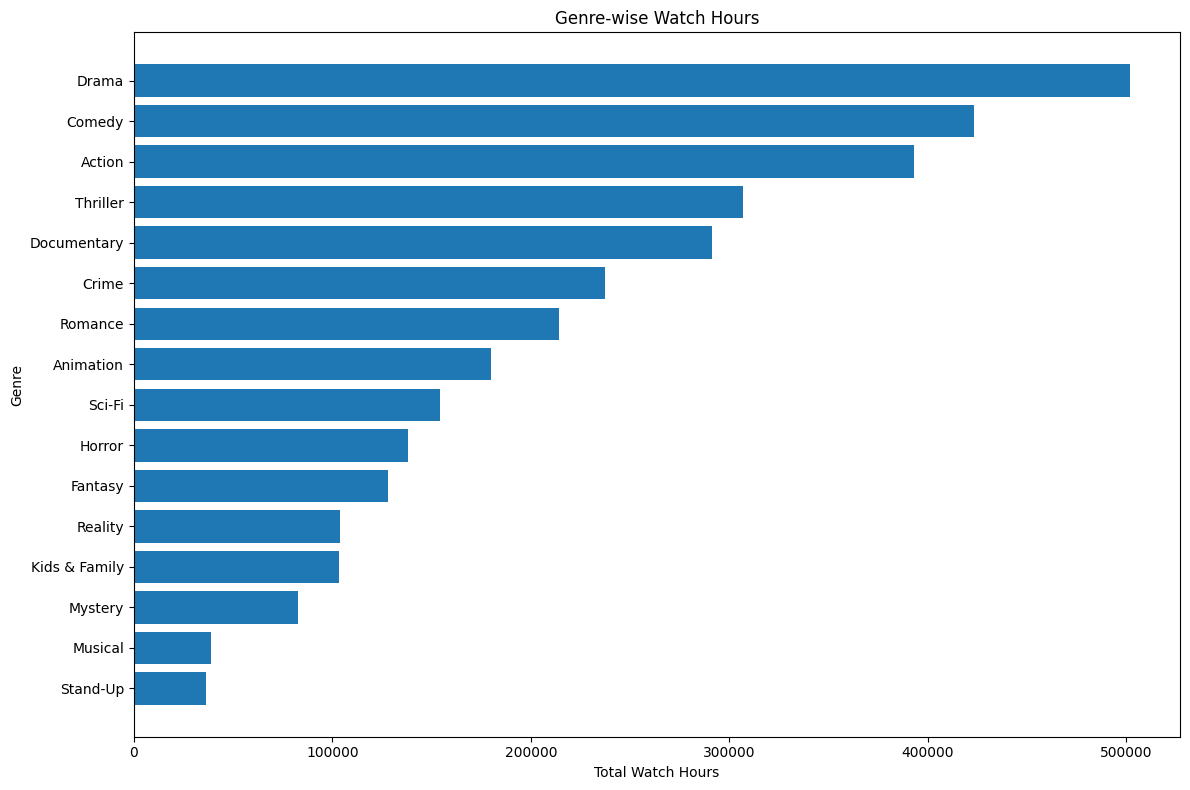

In [ ]:
plt.figure(figsize=(12, 8))

plt.barh(
    genre_watch_hours["primary_genre"],
    genre_watch_hours["watch_hours"]
)

plt.title("Genre-wise Watch Hours")
plt.xlabel("Total Watch Hours")
plt.ylabel("Genre")

# Highest genre at the top
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "/content/03_genre_watch_hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Drama generated the highest watch time with approximately 501,884 hours, followed by Comedy with approximately 423,149 hours and Action with approximately 393,172 hours. Drama therefore has the strongest share of viewing time among the genres, while Stand-Up and Musical recorded the lowest watch hours.

In [ ]:
content_type_watch = watch_history.merge(
    titles[["title_id", "type"]],
    on="title_id",
    how="left"
)

content_type_hours = (
    content_type_watch
    .groupby("type")["watch_duration_min"]
    .sum()
    .div(60)
    .reset_index(name="watch_hours")
)

content_type_hours

,type,watch_hours
0,Movie,4.508588e+05
1,TV Show,2.882609e+06


In [ ]:
content_type_hours["percentage"] = (
    content_type_hours["watch_hours"]
    / content_type_hours["watch_hours"].sum()
) * 100

content_type_hours

,type,watch_hours,percentage
0,Movie,4.508588e+05,13.525219
1,TV Show,2.882609e+06,86.474781


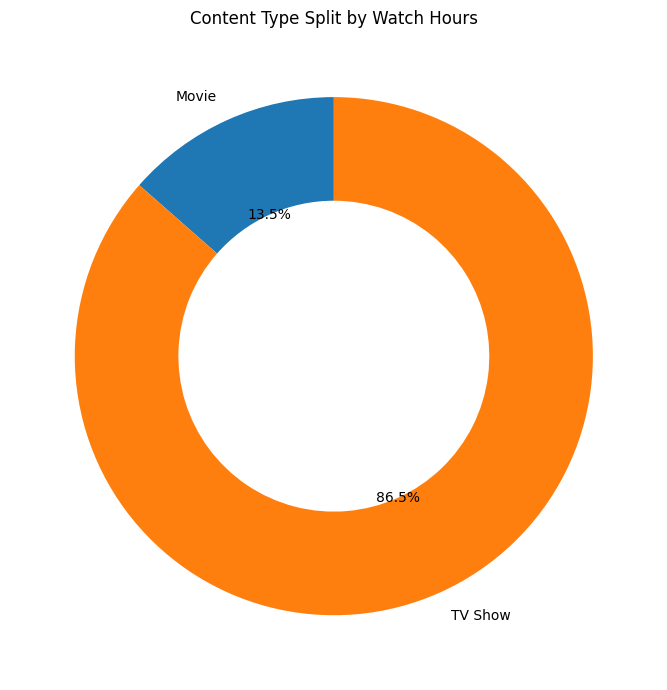

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_type_hours["watch_hours"],
    labels=content_type_hours["type"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4)
)

plt.title("Content Type Split by Watch Hours")

plt.tight_layout()

plt.savefig(
    "/content/04_content_type_watch_hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

TV Shows account for the majority of total watch time, contributing 86.47% of viewing hours, while Movies account for 13.53%. This indicates that TV Show content is the dominant driver of viewing time on StreamFlix.

In [ ]:
country_watch = watch_history.merge(
    titles[["title_id", "country"]],
    on="title_id",
    how="left"
)

country_watch_hours = (
    country_watch
    .groupby("country")["watch_duration_min"]
    .sum()
    .div(60)
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="watch_hours")
)

country_watch_hours

,country,watch_hours
0,United States,822684.680000
1,India,464337.756667
2,United Kingdom,282946.390000
3,South Korea,223476.403333
4,Japan,207130.865000
5,Brazil,176353.601667
6,Mexico,157176.858333
7,Spain,143656.396667
8,France,115011.761667
9,Canada,107072.951667


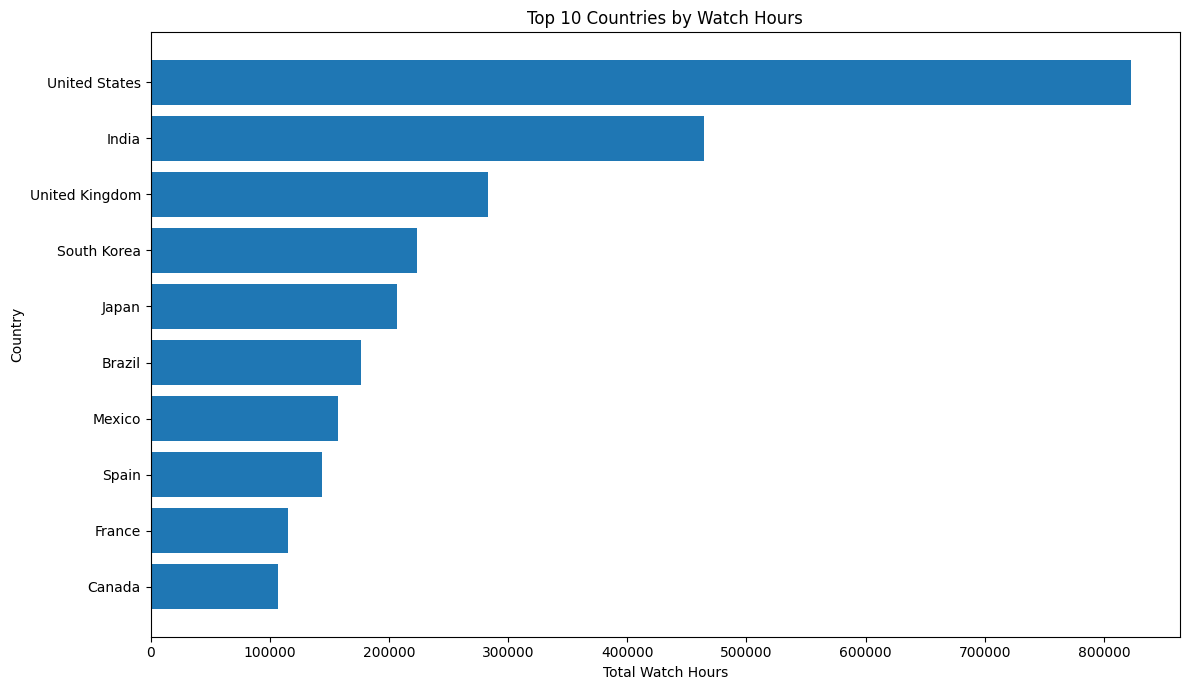

In [ ]:
plt.figure(figsize=(12, 7))

plt.barh(
    country_watch_hours["country"],
    country_watch_hours["watch_hours"]
)

plt.title("Top 10 Countries by Watch Hours")
plt.xlabel("Total Watch Hours")
plt.ylabel("Country")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "/content/05_top_10_countries_watch_hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The United States has the highest watch time with approximately 822,685 hours, followed by India with approximately 464,338 hours. The United Kingdom ranks third with approximately 282,946 hours, while the remaining countries show comparatively lower viewing volumes. This indicates that the United States and India are the strongest markets in terms of total watch time.

In [ ]:
plan_distribution = (
    subscribers["plan_type"]
    .value_counts()
    .reset_index()
)

plan_distribution.columns = ["plan_type", "subscriber_count"]

plan_distribution

,plan_type,subscriber_count
0,Standard,6100
1,Basic with Ads,4458
2,Premium,4442


In [ ]:
plan_distribution = (
    subscribers["plan_type"]
    .value_counts()
    .reset_index()
)

plan_distribution.columns = ["plan_type", "subscriber_count"]

plan_distribution

,plan_type,subscriber_count
0,Standard,6100
1,Basic with Ads,4458
2,Premium,4442


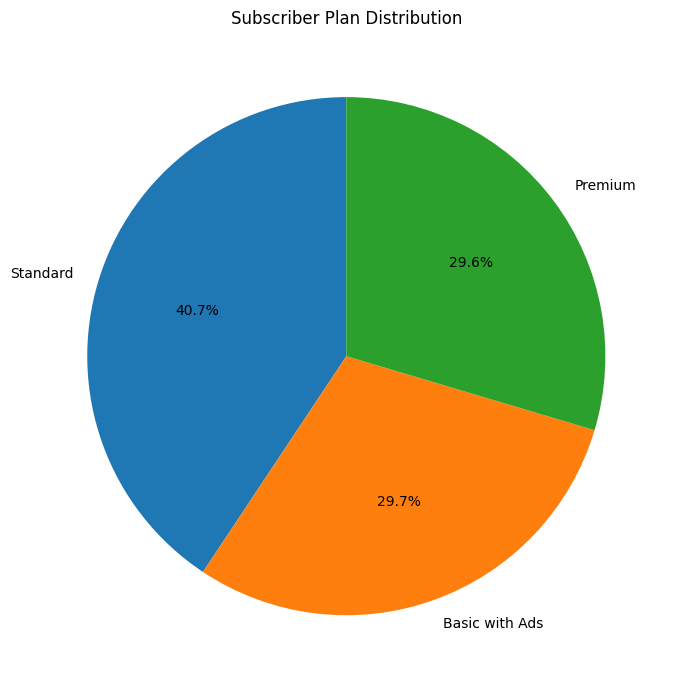

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    plan_distribution["subscriber_count"],
    labels=plan_distribution["plan_type"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Subscriber Plan Distribution")

plt.tight_layout()

plt.savefig(
    "/content/06_subscriber_plan_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The Standard plan has the largest subscriber base with 6,100 subscribers, followed by Basic with Ads with 4,458 subscribers and Premium with 4,442 subscribers. The distribution is relatively balanced between the Basic with Ads and Premium plans, while Standard is the most popular subscription plan.

In [ ]:
device_distribution = (
    subscribers["primary_device"]
    .value_counts()
    .reset_index()
)

device_distribution.columns = ["device", "subscriber_count"]

device_distribution

,device,subscriber_count
0,Smart TV,5045
1,Mobile,4044
2,Laptop,2197
3,Tablet,1538
4,Game Console,1232
5,Streaming Stick,944


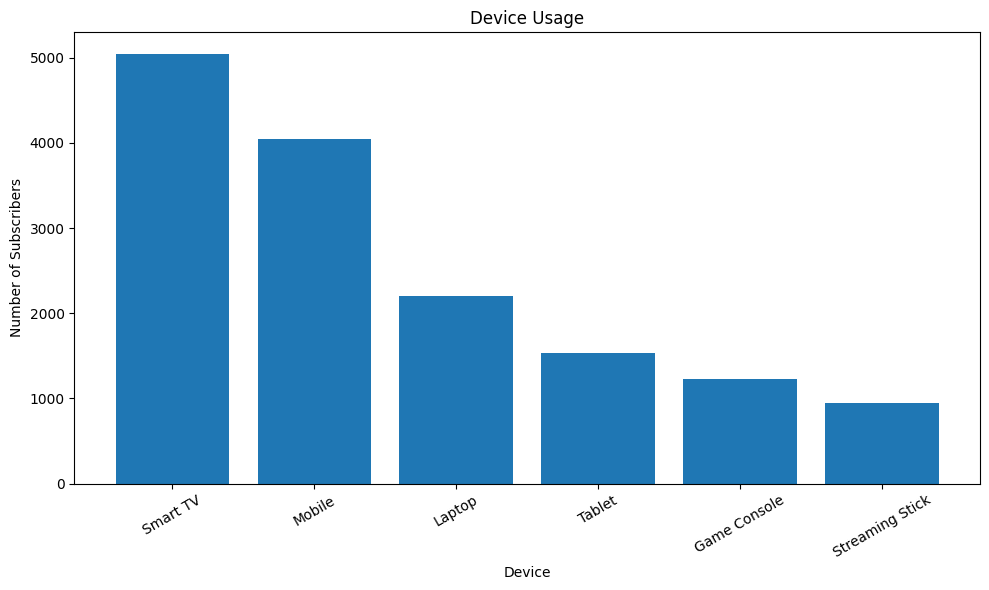

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    device_distribution["device"],
    device_distribution["subscriber_count"]
)

plt.title("Device Usage")
plt.xlabel("Device")
plt.ylabel("Number of Subscribers")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig(
    "/content/07_device_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Smart TV is the most commonly used primary device with 5,045 subscribers, followed by Mobile with 4,044 subscribers. Laptop, Tablet, Game Console, and Streaming Stick have progressively lower usage, indicating that large-screen devices, particularly Smart TVs, are the preferred viewing devices among StreamFlix subscribers.

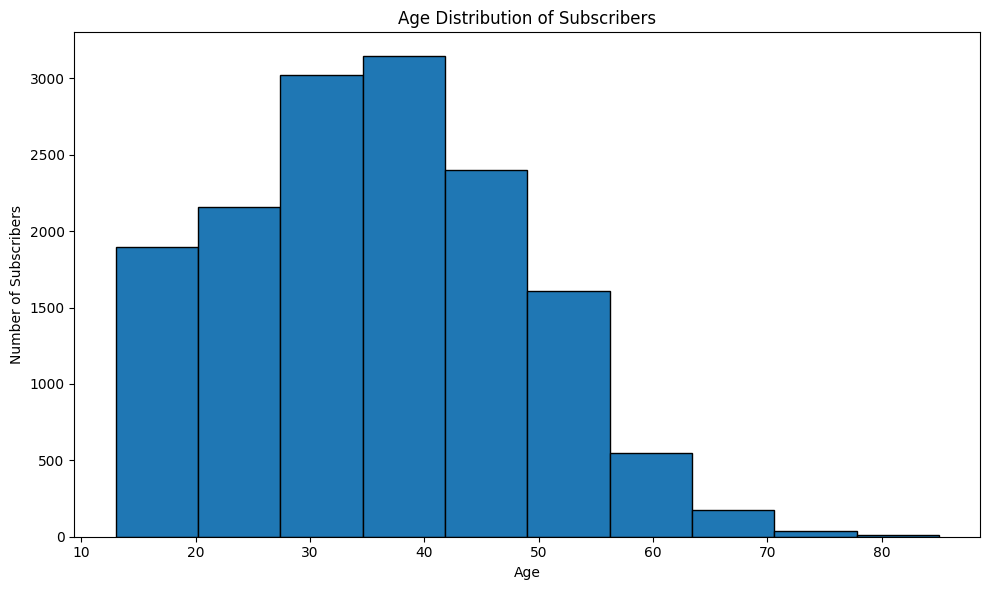

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    subscribers["age"],
    bins=10,
    edgecolor="black"
)

plt.title("Age Distribution of Subscribers")
plt.xlabel("Age")
plt.ylabel("Number of Subscribers")

plt.tight_layout()

plt.savefig(
    "/content/08_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

The subscriber age distribution is concentrated mainly between 25 and 50 years, with the highest number of subscribers falling around the 35–40 age group. Subscriber counts decrease noticeably after age 50, with relatively few subscribers above 65 years.

In [ ]:
genre_completion = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left"
)

genre_completion_rate = (
    genre_completion
    .groupby("primary_genre")["completion_pct"]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="avg_completion_rate")
)

genre_completion_rate

,primary_genre,avg_completion_rate
0,Musical,66.834788
1,Animation,66.383549
2,Stand-Up,66.319730
3,Fantasy,65.968073
4,Sci-Fi,65.793368
5,Mystery,65.558980
6,Crime,65.461294
7,Comedy,65.316334
8,Kids & Family,65.309259
9,Thriller,65.307925


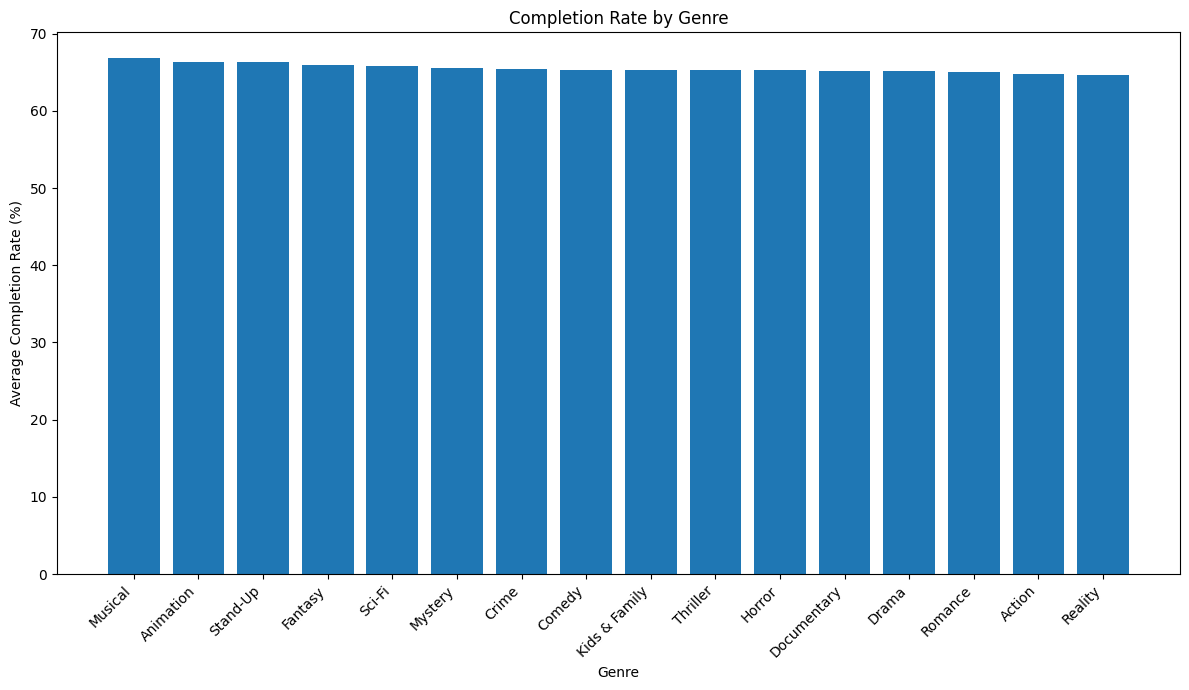

In [ ]:
plt.figure(figsize=(12, 7))

plt.bar(
    genre_completion_rate["primary_genre"],
    genre_completion_rate["avg_completion_rate"]
)

plt.title("Completion Rate by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Completion Rate (%)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "/content/09_completion_rate_by_genre.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Musical content has the highest average completion rate at approximately 66.83%, followed by Animation at 66.38% and Stand-Up at 66.32%. Reality has the lowest completion rate at approximately 64.70%, although the completion rates across all genres are relatively close, ranging from about 64.70% to 66.83%.

In [ ]:
sentiment_distribution = (
    reviews["sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"])
    .reset_index()
)

sentiment_distribution.columns = ["sentiment", "review_count"]

sentiment_distribution

,sentiment,review_count
0,Positive,75007
1,Neutral,22759
2,Negative,12234


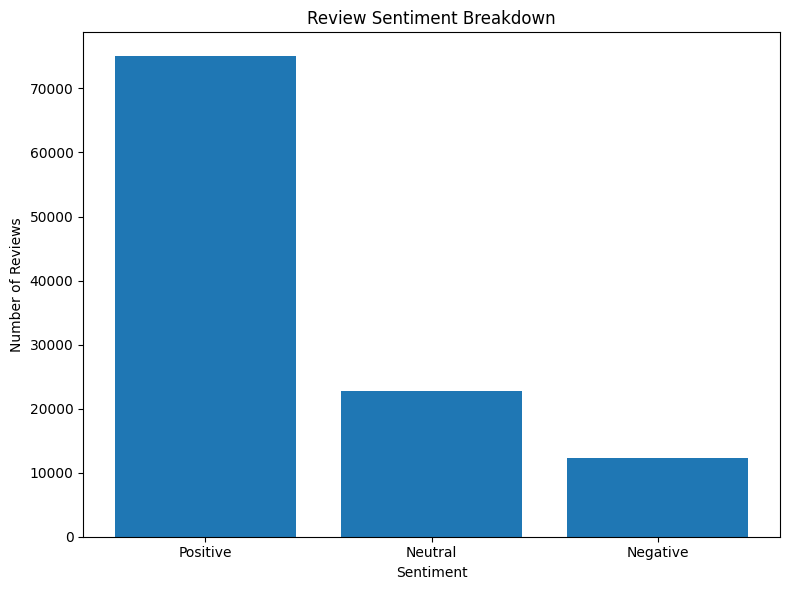

In [ ]:
plt.figure(figsize=(8, 6))

plt.bar(
    sentiment_distribution["sentiment"],
    sentiment_distribution["review_count"]
)

plt.title("Review Sentiment Breakdown")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()

plt.savefig(
    "/content/10_review_sentiment_breakdown.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Observation

Positive reviews are the most common, with 75,007 reviews, followed by 22,759 Neutral reviews and 12,234 Negative reviews. The large number of positive reviews compared with negative reviews indicates an overall favorable customer sentiment toward StreamFlix.